# 01 · Data audit and exploratory analysis

**What this project predicts.** The Graduate Admission dataset contains no observed admission
decisions. Its `Chance of Admit` column is an *estimated* score between 0 and 1. GradMit therefore
does not predict admission. It predicts a **proxy label**:

> `High_Admission_Chance` = 1 when the dataset's estimated Chance of Admit is at or above a selected
> target threshold.

Two thresholds are kept separate throughout:

- the **target threshold** (0.70, 0.75 or 0.80) that defines the label, and
- the **classifier decision threshold** (0.50) applied to a model's predicted probability.

**Provenance.** Mohan S. Acharya, Asfia Armaan and Aneeta S. Antony, *A Comparison of Regression
Models for Prediction of Graduate Admissions*, IEEE ICCIDS 2019, distributed on Kaggle as
"Graduate Admission 2" (`Admission_Predict_Ver1.1.csv`). The copy in `data/Admission_Predict.csv`
is used unchanged.

Run this notebook from the repository root or from `notebooks/`.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "gradmit").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40, "display.width", 200, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
TEAL, OCHRE, SLATE, BRICK = "#0B6E69", "#B7791F", "#6B7C80", "#B4452F"

from gradmit.data import (DATA_PATH, FEATURES, FEATURE_LABELS, SCORE_COLUMN, TARGET_NAME,
                          TARGET_THRESHOLDS, class_balance, data_sha256, load_data, make_target)
from gradmit.statistics import research_association

df = load_data()
print("file:", DATA_PATH.relative_to(ROOT).as_posix())
print("sha256:", data_sha256())
print("shape:", df.shape)
df.head()

file: data/Admission_Predict.csv
sha256: 9559c8d163696f5521a57e5d0c97b01e07b02fcfa36125c0fa2b934213f12186
shape: (500, 8)


,GRE_Score,TOEFL_Score,University_Rating,SOP,LOR,CGPA,Research,Chance_of_Admit
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72
3,322,110,3,3.5,2.5,8.67,1,0.80
4,314,103,2,2.0,3.0,8.21,0,0.65


## Schema, missing values and duplicates

In [2]:
audit = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(),
                      "unique": df.nunique(), "min": df.min(), "max": df.max()})
display(audit)
print("rows:", len(df), "| missing cells:", int(df.isna().sum().sum()),
      "| duplicate rows:", int(df.duplicated().sum()))
df.describe().T

,dtype,missing,unique,min,max
GRE_Score,int64,0,49,290.00,340.00
TOEFL_Score,int64,0,29,92.00,120.00
University_Rating,int64,0,5,1.00,5.00
SOP,float64,0,9,1.00,5.00
LOR,float64,0,9,1.00,5.00
CGPA,float64,0,184,6.80,9.92
Research,int64,0,2,0.00,1.00
Chance_of_Admit,float64,0,61,0.34,0.97


rows: 500 | missing cells: 0 | duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
GRE_Score,500.0,316.472,11.295,290.00,308.000,317.00,325.00,340.00
TOEFL_Score,500.0,107.192,6.082,92.00,103.000,107.00,112.00,120.00
University_Rating,500.0,3.114,1.144,1.00,2.000,3.00,4.00,5.00
SOP,500.0,3.374,0.991,1.00,2.500,3.50,4.00,5.00
LOR,500.0,3.484,0.925,1.00,3.000,3.50,4.00,5.00
CGPA,500.0,8.576,0.605,6.80,8.128,8.56,9.04,9.92
Research,500.0,0.560,0.497,0.00,0.000,1.00,1.00,1.00
Chance_of_Admit,500.0,0.722,0.141,0.34,0.630,0.72,0.82,0.97


## Target construction and class balance

`make_target` is the single place the proxy label is defined; every script, test and app page
imports it.

In [3]:
balance = pd.DataFrame([class_balance(df, t) for t in TARGET_THRESHOLDS])
expected = {0.70: 300, 0.75: 218, 0.80: 155}
assert {r.target_threshold: r.n_positive for r in balance.itertuples()} == expected
balance.assign(positive_share=lambda d: (d.positive_share * 100).round(1),
               majority_accuracy=lambda d: (d.majority_accuracy * 100).round(1))

,target_threshold,n,n_positive,n_negative,positive_share,majority_accuracy
0,0.70,500,300,200,60.0,60.0
1,0.75,500,218,282,43.6,56.4
2,0.80,500,155,345,31.0,69.0


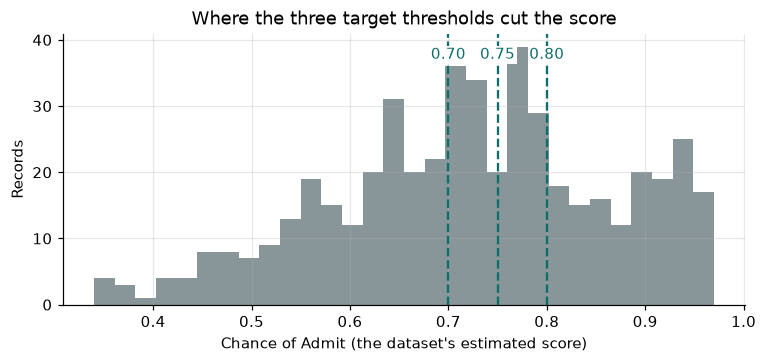

**Reading the cut.** The label is a cut on a continuous estimate. 144 of 500 records sit within 0.05 of the 0.70 threshold; 158 of 500 records sit within 0.05 of the 0.75 threshold; 115 of 500 records sit within 0.05 of the 0.80 threshold. Those records are labelled almost arbitrarily, which limits how accurate any classifier can be.

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(df[SCORE_COLUMN], bins=30, color=SLATE, alpha=0.8)
for t in TARGET_THRESHOLDS:
    ax.axvline(t, color=TEAL, ls="--", lw=1.5)
    ax.text(t, ax.get_ylim()[1] * 0.95, f"{t:.2f}", color=TEAL, ha="center", va="top",
            bbox=dict(fc="white", ec="none", pad=1))
ax.set(xlabel="Chance of Admit (the dataset's estimated score)", ylabel="Records",
       title="Where the three target thresholds cut the score")
plt.show()

near = {t: int((df[SCORE_COLUMN].sub(t).abs().round(4) <= 0.05).sum()) for t in TARGET_THRESHOLDS}
display(Markdown("**Reading the cut.** The label is a cut on a continuous estimate. "
    + "; ".join(f"{n} of {len(df)} records sit within 0.05 of the {t:.2f} threshold" for t, n in near.items())
    + ". Those records are labelled almost arbitrarily, which limits how accurate any classifier can be."))

## Feature distributions by proxy class (target threshold 0.75)

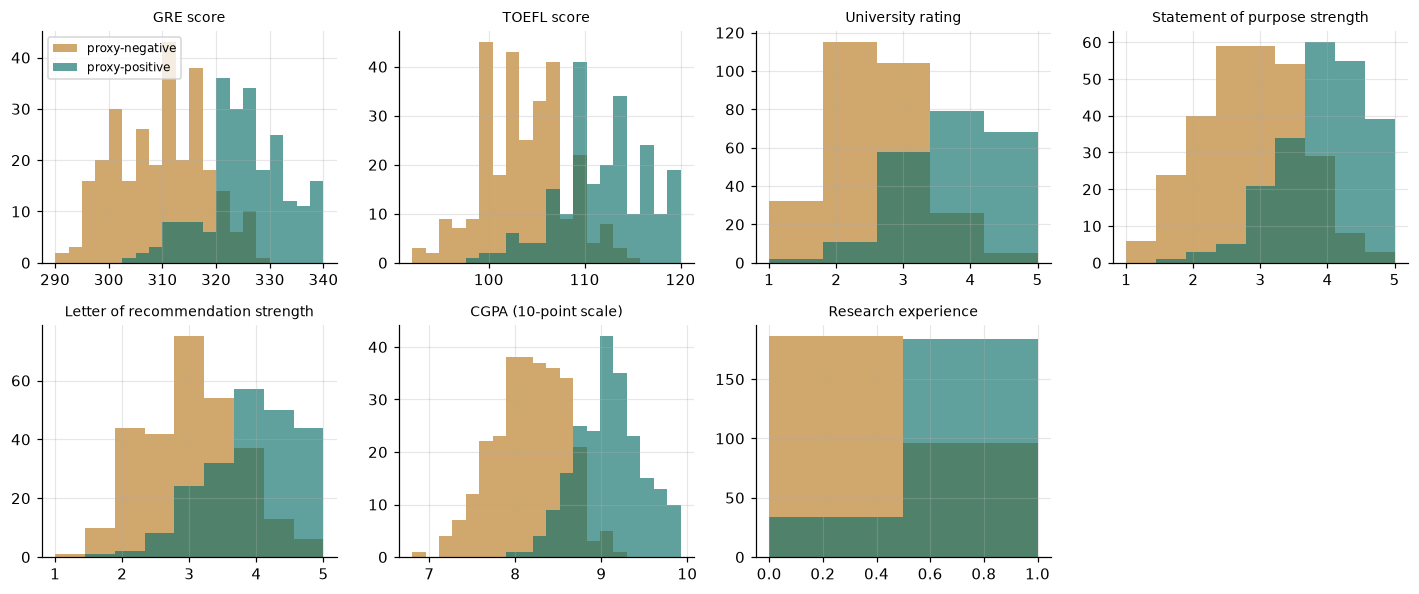

,proxy-negative mean,proxy-positive mean
GRE_Score,309.511,325.477
TOEFL_Score,103.557,111.894
University_Rating,2.493,3.917
SOP,2.846,4.057
LOR,3.048,4.048
CGPA,8.177,9.093
Research,0.340,0.844


In [5]:
y = make_target(df, 0.75)
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, f in zip(axes.ravel(), FEATURES):
    bins = np.histogram_bin_edges(df[f], bins=min(20, df[f].nunique()))
    ax.hist(df.loc[y == 0, f], bins=bins, color=OCHRE, alpha=0.65, label="proxy-negative")
    ax.hist(df.loc[y == 1, f], bins=bins, color=TEAL, alpha=0.65, label="proxy-positive")
    ax.set_title(FEATURE_LABELS[f], fontsize=9)
axes.ravel()[0].legend(fontsize=8)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

means = df.assign(**{TARGET_NAME: y}).groupby(TARGET_NAME)[FEATURES].mean().T
means.columns = ["proxy-negative mean", "proxy-positive mean"]
means

## Research experience and high estimated admission chance

The question is: *among records with (or without) research experience, what share is above the
threshold?* That is `P(proxy-positive | Research status)`, so the data must be grouped by
`Research` first.

An earlier version of this project grouped by the label instead and so reported
`P(Research = 1 | label)` under "Has research / No research" captions. Both quantities are computed
below so the difference is explicit.

In [6]:
research = pd.concat([research_association(df, t) for t in TARGET_THRESHOLDS], ignore_index=True)
display(research.assign(positive_rate=lambda d: (d.positive_rate * 100).round(1),
                        ci_low=lambda d: (d.ci_low * 100).round(1),
                        ci_high=lambda d: (d.ci_high * 100).round(1)))

r75 = research[research.target_threshold == 0.75].set_index("research")
with_research = df[df["Research"] == 1]
without_research = df[df["Research"] == 0]
assert np.isclose(r75.loc[1, "positive_rate"], make_target(with_research, 0.75).mean())
assert np.isclose(r75.loc[0, "positive_rate"], make_target(without_research, 0.75).mean())

reversed_pos = df.loc[y == 1, "Research"].mean()
reversed_neg = df.loc[y == 0, "Research"].mean()
display(Markdown(
    f"**Correct direction (threshold 0.75).** Has research: {r75.loc[1, 'positive_rate']:.1%} proxy-positive "
    f"(n = {r75.loc[1, 'n']}); no research: {r75.loc[0, 'positive_rate']:.1%} (n = {r75.loc[0, 'n']}).\n\n"
    f"**Reversed quantity, not what the chart shows.** P(Research = 1 | proxy-positive) = {reversed_pos:.1%} and "
    f"P(Research = 1 | proxy-negative) = {reversed_neg:.1%}. These answer a different question and must not be "
    "labelled by research group."))

,target_threshold,research,group,n,n_positive,positive_rate,ci_low,ci_high
0,0.70,1,Has research,280,225,80.4,75.3,84.6
1,0.70,0,No research,220,75,34.1,28.1,40.6
2,0.75,1,Has research,280,184,65.7,60.0,71.0
3,0.75,0,No research,220,34,15.5,11.3,20.8
4,0.80,1,Has research,280,144,51.4,45.6,57.2
5,0.80,0,No research,220,11,5.0,2.8,8.7


**Correct direction (threshold 0.75).** Has research: 65.7% proxy-positive (n = 280); no research: 15.5% (n = 220).

**Reversed quantity, not what the chart shows.** P(Research = 1 | proxy-positive) = 84.4% and P(Research = 1 | proxy-negative) = 34.0%. These answer a different question and must not be labelled by research group.

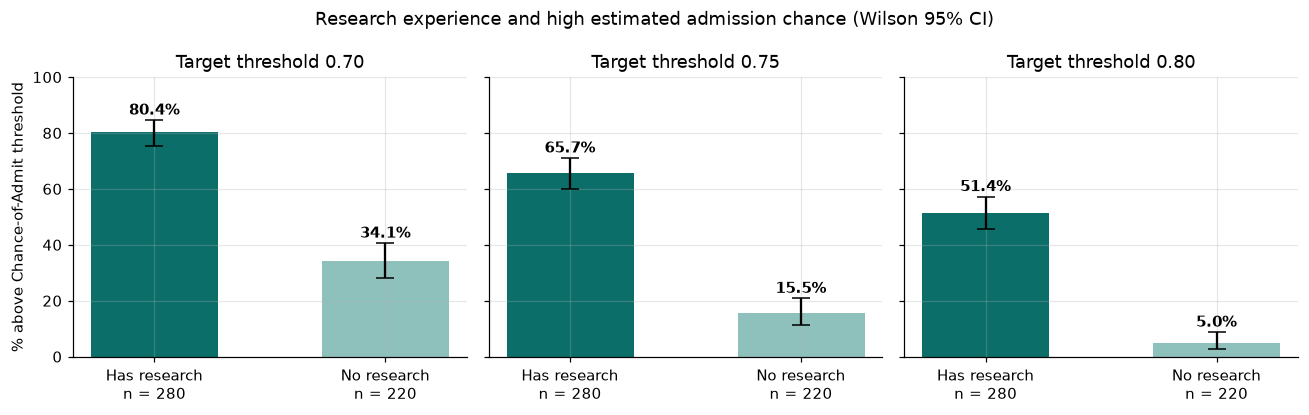

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, t in zip(axes, TARGET_THRESHOLDS):
    r = research[research.target_threshold == t].sort_values("research", ascending=False)
    rate = r.positive_rate * 100
    err = np.vstack([rate - r.ci_low * 100, r.ci_high * 100 - rate])
    ax.bar([f"{g}\nn = {n}" for g, n in zip(r.group, r.n)], rate, yerr=err, capsize=6,
           color=[TEAL, "#8FC1BC"], width=0.55)
    for i, (v, hi) in enumerate(zip(rate, r.ci_high * 100)):
        ax.text(i, hi + 2, f"{v:.1f}%", ha="center", fontweight="bold")
    ax.set(title=f"Target threshold {t:.2f}", ylim=(0, 100))
axes[0].set_ylabel("% above Chance-of-Admit threshold")
fig.suptitle("Research experience and high estimated admission chance (Wilson 95% CI)")
plt.tight_layout(); plt.show()

**This is an association, not a causal effect.** Records with research experience also differ on
every other feature (next section), and the score being cut is itself an estimate. Nothing here
says what research experience does to anyone's chances.

## Correlation, with caveats

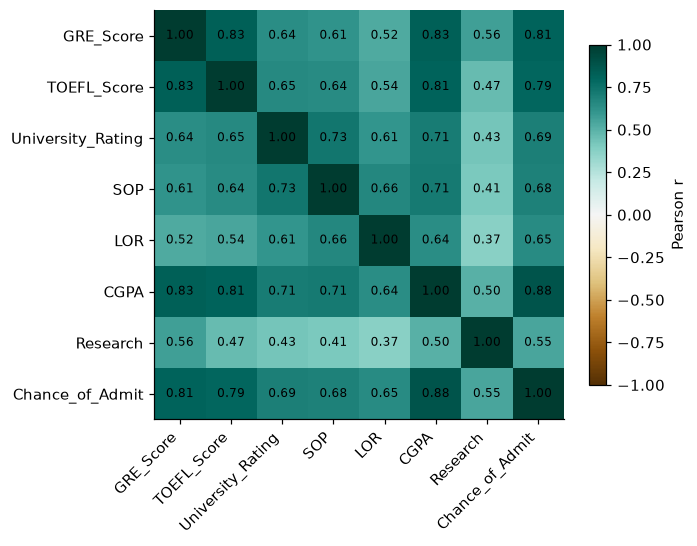

**Caveats.** The feature most correlated with the score is `CGPA` (r = 0.88). Features are also correlated with each other: pairwise r ranges from 0.37 to 0.83. With predictors this entangled, no single feature can be credited with the score, and a correlation in 500 records says nothing about what would happen if one value changed.

In [8]:
corr = df[FEATURES + [SCORE_COLUMN]].corr()
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False); fig.colorbar(im, shrink=0.8, label="Pearson r")
plt.tight_layout(); plt.show()

feat = corr.loc[FEATURES, FEATURES].where(~np.eye(len(FEATURES), dtype=bool))
top = corr[SCORE_COLUMN].drop(SCORE_COLUMN).sort_values(ascending=False)
display(Markdown(
    f"**Caveats.** The feature most correlated with the score is `{top.index[0]}` (r = {top.iloc[0]:.2f}). "
    f"Features are also correlated with each other: pairwise r ranges from {feat.min().min():.2f} to "
    f"{feat.max().max():.2f}. With predictors this entangled, no single feature can be credited with the "
    "score, and a correlation in 500 records says nothing about what would happen if one value changed."))

## Limitations carried into the modelling notebooks

- No real outcomes: the label is derived from an estimate, so no result here is validated against an
  admission decision.
- One small sample from a single source, concentrated among strong applicants.
- A thresholded continuous score: records near the cut are inherently ambiguous.
- Observational data: every relationship is an association.